<a href="https://colab.research.google.com/github/MarcinPlodzien/deep-learning-for-classical-and-quantum-physics/blob/main/notebooks/lecture-08/lab-044-predator-prey.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"></a>

<hr/>
# Deep Learning in Classical and Quantum Physics
2026/2027 <br>
**Author:** Marcin Płodzień <br>
**Lab:** 044 <br>
<hr/>

# Lab 044 — Predator–prey with unknown interaction

Two interacting populations, a prey that breeds and a predator that eats it, form the classic example of nonlinear population dynamics. The growth of isolated prey and the death of starving predators are easy to measure in separate experiments, while the way the two species interact is the uncertain part of any model. In this notebook we keep the two single-species terms and let a neural network $\mathbf U_\theta$ represent the interaction inside the differential equations. A universal differential equation of this kind is trained through the ODE solver on noisy population counts [C. Rackauckas *et al.*, [arXiv:2001.04385](https://arxiv.org/abs/2001.04385)], and sparse regression [S. L. Brunton, J. L. Proctor, J. N. Kutz, PNAS **113**, 3932 (2016), [doi:10.1073/pnas.1517384113](https://doi.org/10.1073/pnas.1517384113)] then searches for a formula for the learned interaction.

We start from the Lotka–Volterra equations, their fixed point, their closed orbits and their conserved quantity, and then introduce a predator that saturates when food is abundant, the Holling type II functional response, together with a finite carrying capacity of the prey. This model generates the data. Three models are fitted to the data, the textbook Lotka–Volterra equations with fitted rates, a pure neural ordinary differential equation (neural ODE) [R. T. Q. Chen *et al.*, [arXiv:1806.07366](https://arxiv.org/abs/1806.07366)] and the hybrid model. The saturating interaction is a rational function, and we show what sparse regression with a library linear in its coefficients can and cannot recover from it. In the last part the prey growth rate follows a seasonal cycle, and we compare a hybrid model that receives the season as an input with one that does not.

The implementation uses JAX. The fourth-order Runge–Kutta integrator, the networks, the training loop with `jax.grad` and the `optax` Adam optimiser, and the sparse regression are written as short functions in the notebook, and the integrator is compared with the adaptive solvers of the `diffrax` library.

> **How to run this notebook in Google Colab**
> 1. Go to <https://colab.research.google.com> → *File → Upload notebook*. The first code cell sets `JAX_PLATFORMS=cpu`. The whole notebook runs in a few minutes on a multi-core CPU.
> 2. `jax`, `optax` and `matplotlib` are pre-installed in Colab. The ODE library is installed with `pip install diffrax`.
> 3. Run the cells *in order*. Later cells use variables defined earlier.

In [1]:
import os
os.environ["JAX_PLATFORMS"] = "cpu"     # run JAX on the CPU (set before importing jax)

import json, time
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, FancyBboxPatch, FancyArrowPatch

import jax, jax.numpy as jnp
jax.config.update("jax_enable_x64", True)   # all trajectories, networks and regressions in float64
import optax
import diffrax

# common style of the notebook figures
mpl.rcParams.update({"font.size": 14, "axes.labelsize": 15, "axes.titlesize": 15,
                     "xtick.labelsize": 13, "ytick.labelsize": 13, "legend.fontsize": 12,
                     "figure.titlesize": 16, "lines.linewidth": 2.0,
                     "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False})
# slide figures are drawn at their printed size (5.5 in = full width of a slide), so these are true font sizes
SLIDE_RC = {"font.size": 11, "axes.labelsize": 11, "axes.titlesize": 11, "xtick.labelsize": 11,
            "ytick.labelsize": 11, "legend.fontsize": 11, "lines.linewidth": 1.4, "figure.dpi": 150}

UJBlue, UJNavy, DSOrange, UJGray = "#005CA7", "#002B5C", "#D35A05", "#5A6270"
PREY, PRED = UJBlue, DSOrange                 # colours of the prey x and the predator y
# one colour and line style per model, used in every figure
STYLE = {"truth": dict(color="k", ls="-"), "Lotka-Volterra fit": dict(color="0.55", ls=":"),
         "neural ODE": dict(color="#7B4FA0", ls="--"), "hybrid": dict(color=DSOrange, ls="-"),
         "polynomial formula": dict(color="#2A9D8F", ls=":"), "rational formula": dict(color=UJBlue, ls="-."),
         "refitted formula": dict(color="#C0392B", ls="--")}

OUT = "figures"
os.makedirs(OUT, exist_ok=True)
def save(fig, name):
    # slide figures are created at their printed size and saved as PDF (slides) and PNG
    for ext in ("pdf", "png"):
        fig.savefig(f"{OUT}/{name}.{ext}", dpi=300, bbox_inches="tight", pad_inches=0.02)

nums = {}                 # every number a slide may need, written to the numbers file at the end
t_start = time.time()
print("jax", jax.__version__, "| optax", optax.__version__, "| diffrax", diffrax.__version__)

jax 0.11.0 | optax 0.2.6 | diffrax 0.7.2


<hr/>
## 1. Lotka–Volterra equations

Let $x(t)$ be the number of prey and $y(t)$ the number of predators, both measured in units of some reference population, for example thousands of animals. Lotka and Volterra proposed independently [A. J. Lotka, PNAS **6**, 410 (1920), [doi:10.1073/pnas.6.7.410](https://doi.org/10.1073/pnas.6.7.410); V. Volterra, Nature **118**, 558 (1926), [doi:10.1038/118558a0](https://doi.org/10.1038/118558a0)]
$$\dot x=\alpha x-\beta xy,\qquad \dot y=-\delta y+\gamma xy .$$
Each term has a direct meaning. Prey breed at the rate $\alpha$ per animal. Predators meet prey at a rate proportional to the product $xy$, as two species moving at random in the same area do, and each encounter removes prey at the rate $\beta xy$. Predators starve at the rate $\delta$ per animal without food and grow at the rate $\gamma xy$ from the prey they eat, so $\gamma/\beta$ is the number of predators produced per prey eaten. All four rates are positive.

Setting both right-hand sides to zero gives the coexistence fixed point $x^*=\delta/\gamma$, $y^*=\alpha/\beta$. Dividing the two equations removes the time, $dy/dx=y(\gamma x-\delta)/[x(\alpha-\beta y)]$, and the separated equation integrates to the conserved quantity
$$V(x,y)=\gamma x-\delta\ln x+\beta y-\alpha\ln y,\qquad \dot V=\Big(\gamma-\frac{\delta}{x}\Big)\dot x+\Big(\beta-\frac{\alpha}{y}\Big)\dot y=0 .$$
$V$ has its minimum at the fixed point, so every other orbit is a closed curve $V={\rm const}$ around it, and the populations oscillate forever with an amplitude set by the initial condition. We use $\alpha=\beta=\gamma=1$ and $\delta=0.8$, so $x^*=0.8$ and $y^*=1$, integrate several orbits with the fourth-order Runge–Kutta (RK4) method and check that $V$ stays constant.

In [2]:
def rk4_step(f, s, t, h):
    k1 = f(s, t)
    k2 = f(s + 0.5 * h * k1, t + 0.5 * h)
    k3 = f(s + 0.5 * h * k2, t + 0.5 * h)
    k4 = f(s + h * k3, t + h)
    return s + h / 6.0 * (k1 + 2 * k2 + 2 * k3 + k4)

def rk4_solve(f, s0, t0, n_steps, h, sub=1):
    # states at t0, t0 + h, ..., t0 + n_steps h; each stored interval is split into `sub` RK4 steps
    def body(s, i):
        t = t0 + i * h
        for j in range(sub):
            s = rk4_step(f, s, t + j * h / sub, h / sub)
        return s, s
    _, S = jax.lax.scan(body, s0, jnp.arange(n_steps))
    return jnp.concatenate([s0[None], S])

ALPHA, BETA, GAMMA, DELTA = 1.0, 1.0, 1.0, 0.8      # prey growth, predation, predator gain, predator death

def lotka_volterra(a=ALPHA, b=BETA, g=GAMMA, d=DELTA):
    return lambda s, t: jnp.array([a * s[0] - b * s[0] * s[1], -d * s[1] + g * s[0] * s[1]])

def V_lv(S, a=ALPHA, b=BETA, g=GAMMA, d=DELTA):
    x, y = np.asarray(S)[..., 0], np.asarray(S)[..., 1]
    return g * x - d * np.log(x) + b * y - a * np.log(y)

x_star, y_star = DELTA / GAMMA, ALPHA / BETA
lv_orbits = {}
for x0 in (1.2, 1.8, 2.6, 3.6):
    S = np.asarray(rk4_solve(lotka_volterra(), jnp.array([x0, y_star]), 0.0, 3000, 0.01))   # 0 <= t <= 30
    V = V_lv(S)
    lv_orbits[x0] = S
    print(f"x(0) = {x0}: V = {V[0]:.6f}, max |V(t) - V(0)| / V(0) = {np.abs(V - V[0]).max() / V[0]:.1e}")
nums["lv_V_drift_max"] = float(max(np.abs(V_lv(S) - V_lv(S)[0]).max() / V_lv(S)[0] for S in lv_orbits.values()))
J = jax.jacfwd(lambda s: lotka_volterra()(s, 0.0))(jnp.array([x_star, y_star]))
print("fixed point", (x_star, y_star), "| eigenvalues of the Jacobian", np.round(np.linalg.eigvals(np.asarray(J)), 4))

x(0) = 1.2: V = 2.054143, max |V(t) - V(0)| / V(0) = 4.6e-12
x(0) = 1.8: V = 2.329771, max |V(t) - V(0)| / V(0) = 6.4e-11
x(0) = 2.6: V = 2.835591, max |V(t) - V(0)| / V(0) = 4.8e-10
x(0) = 3.6: V = 3.575253, max |V(t) - V(0)| / V(0) = 3.1e-09


fixed point (0.8, 1.0) | eigenvalues of the Jacobian [0.+0.8944j 0.-0.8944j]


The relative change of $V$ along every orbit is at the level of the RK4 error, so the numerical orbits close on themselves. The eigenvalues of the Jacobian at the fixed point are purely imaginary, $\pm i\sqrt{\alpha\delta}$, the linear signature of a centre. The figure shows the four orbits in the phase plane on the left and the populations of the largest one in time on the right. The predator maximum follows the prey maximum, since predators multiply only after food has become plentiful.

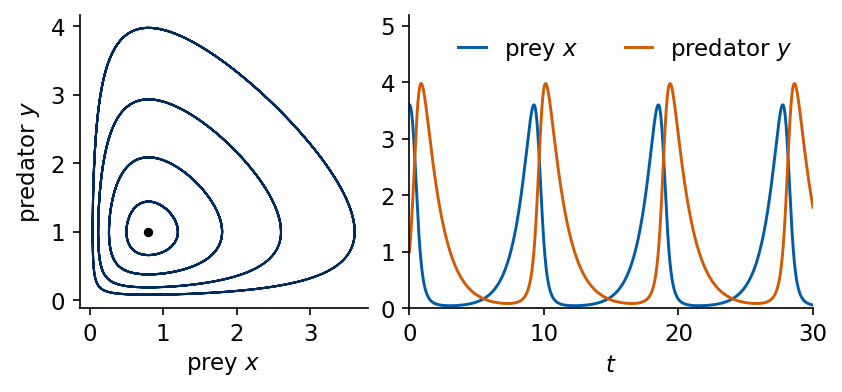

In [3]:
with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(1, 2, figsize=(5.5, 2.5), layout="constrained", gridspec_kw={"width_ratios": [1, 1.4]})
    for x0, S in lv_orbits.items():
        axs[0].plot(S[:, 0], S[:, 1], color=UJNavy, lw=1.0)
    axs[0].plot(x_star, y_star, "o", color="k", ms=3.5)
    axs[0].set_xlabel("prey $x$"); axs[0].set_ylabel("predator $y$")
    S = lv_orbits[3.6]; t = np.arange(len(S)) * 0.01
    axs[1].plot(t, S[:, 0], color=PREY, label="prey $x$"); axs[1].plot(t, S[:, 1], color=PRED, label="predator $y$")
    axs[1].set_xlabel("$t$"); axs[1].set_xlim(0, 30)
    axs[1].legend(loc="upper right", ncol=2, handlelength=1.2)
    axs[1].set_ylim(0, 5.2)
    save(fig, "fig_lab044_lotka_volterra"); plt.show()

### Saturating predator and limited prey

The product $\beta xy$ assumes that each predator eats more the more prey there is, without limit. A real predator needs time to handle each prey, and Holling showed that the number of prey eaten per predator and unit time then saturates [C. S. Holling, Can. Entomol. **91**, 385 (1959), [doi:10.4039/Ent91385-7](https://doi.org/10.4039/Ent91385-7)]. If a predator searches at the rate $\beta$ and spends the handling time $h/\beta$ on each prey, the fraction of its time spent searching is $1/(1+hx)$, and the consumption per predator becomes the type II functional response
$$\varphi(x)=\frac{\beta x}{1+hx},$$
linear for $x\ll1/h$ and saturating at $\beta/h$ for $x\gg1/h$. Prey without predators also stop growing at a carrying capacity $K$ set by their own food supply. Both changes together give the Rosenzweig–MacArthur model [M. L. Rosenzweig, R. H. MacArthur, Am. Nat. **97**, 209 (1963), [doi:10.1086/282272](https://doi.org/10.1086/282272)],
$$\dot x=\alpha x-\frac{\alpha}{K}x^2-\frac{\beta xy}{1+hx},\qquad \dot y=-\delta y+\frac{\gamma xy}{1+hx},$$
which is the hidden truth of this notebook, with $h=0.5$ and $K=6$ and the rates above. The coexistence fixed point moves to $x^*=\delta/(\gamma-\delta h)$, $y^*=(\alpha/\beta)(1-x^*/K)(1+hx^*)$. Saturation weakens the predator at high prey density, and for these parameters the fixed point becomes an unstable focus. The trajectories spiral away from it onto a limit cycle, a single closed orbit that attracts all nearby trajectories, so that the amplitude of the oscillation no longer depends on the initial condition. The function $V$ is no longer conserved. We verify the instability through the eigenvalues of the Jacobian and measure the period and the prey range of the limit cycle.

In [4]:
H_SAT, K_CAP = 0.5, 6.0          # saturation constant h and carrying capacity K

def interaction(x, y, h=H_SAT):
    # Holling type II encounter term x y / (1 + h x)
    return x * y / (1 + h * x)

def rosenzweig_macarthur(season=0.0, omega=2 * np.pi / 20):
    # hidden truth; season > 0 makes the prey growth rate alpha (1 + season sin(omega t))
    def f(s, t):
        x, y = s[0], s[1]
        a_t = ALPHA * (1 + season * jnp.sin(omega * t))
        return jnp.array([a_t * x - ALPHA / K_CAP * x ** 2 - BETA * interaction(x, y), -DELTA * y + GAMMA * interaction(x, y)])
    return f

def U_true(S):
    # the part of the vector field the hybrid model must learn: everything except alpha x and -delta y
    x, y = np.asarray(S)[..., 0], np.asarray(S)[..., 1]
    return np.stack([-ALPHA / K_CAP * x ** 2 - BETA * interaction(x, y), GAMMA * interaction(x, y)], -1)

xs_rm = DELTA / (GAMMA - DELTA * H_SAT)
ys_rm = ALPHA / BETA * (1 - xs_rm / K_CAP) * (1 + H_SAT * xs_rm)
J = jax.jacfwd(lambda s: rosenzweig_macarthur()(s, 0.0))(jnp.array([xs_rm, ys_rm]))
ev = np.linalg.eigvals(np.asarray(J))
print(f"fixed point x* = {xs_rm:.4f}, y* = {ys_rm:.4f} | eigenvalues {np.round(ev, 4)}")

def peaks(t, x):
    # times and values of the local maxima of x(t)
    k = np.nonzero((x[1:-1] > x[:-2]) & (x[1:-1] >= x[2:]))[0] + 1
    return t[k], x[k]

def cycle_stats(t, S, t_from):
    # period (mean spacing of prey maxima) and prey range for t >= t_from
    sel = t >= t_from
    tp, _ = peaks(t[sel], S[sel, 0])
    return dict(period=float(np.diff(tp).mean()) if len(tp) > 1 else float("nan"),
                x_min=float(S[sel, 0].min()), x_max=float(S[sel, 0].max()),
                y_min=float(S[sel, 1].min()), y_max=float(S[sel, 1].max()))

DT, T_TRAIN, T_END = 0.1, 40.0, 200.0
N_TRAIN, N_END = int(round(T_TRAIN / DT)), int(round(T_END / DT))
t_grid = np.arange(N_END + 1) * DT
S0_TRUE = jnp.array([2.0, 1.3])
true = np.asarray(rk4_solve(rosenzweig_macarthur(), S0_TRUE, 0.0, N_END, DT, sub=10))
cyc_true = cycle_stats(t_grid, true, 150.0)
print("limit cycle for 150 <= t <= 200:", {k: round(v, 3) for k, v in cyc_true.items()})
nums["fixed_point_rm"] = [xs_rm, ys_rm]; nums["eig_rm_real"] = float(ev.real.max())
nums["cycle_true"] = cyc_true

fixed point x* = 1.3333, y* = 1.2963 | eigenvalues [0.0444+0.6094j 0.0444-0.6094j]


limit cycle for 150 <= t <= 200: {'period': 12.533, 'x_min': 0.208, 'x_max': 4.198, 'y_min': 0.246, 'y_max': 3.031}


The real part of the eigenvalues is positive, so small deviations from the fixed point grow while they rotate around it. The adaptive eighth-order Dormand–Prince solver `Dopri8` of `diffrax` [P. Kidger, *On Neural Differential Equations*, PhD thesis, [arXiv:2202.02435](https://arxiv.org/abs/2202.02435)] with tolerances $10^{-11}$ integrates the same equations as a check of our RK4 trajectory up to $t=200$.

In [5]:
def diffrax_solve(f, s0, ts, solver=diffrax.Dopri8(), tol=1e-11):
    # adaptive diffrax solution of ds/dt = f(s, t), stored at the times ts
    term = diffrax.ODETerm(lambda t, s, args: f(s, t))
    sol = diffrax.diffeqsolve(term, solver, ts[0], ts[-1], 0.01, s0, saveat=diffrax.SaveAt(ts=ts),
                              stepsize_controller=diffrax.PIDController(rtol=tol, atol=tol), max_steps=400_000)
    return sol.ys

ref = np.asarray(diffrax_solve(rosenzweig_macarthur(), S0_TRUE, jnp.asarray(t_grid)))
print(f"max |RK4 - Dopri8| for 0 <= t <= 200: {np.abs(ref - true).max():.1e}")
nums["rk4_vs_dopri8"] = float(np.abs(ref - true).max())

max |RK4 - Dopri8| for 0 <= t <= 200: 2.8e-09


The two solutions agree to the printed accuracy. The left panel of the next figure compares the Holling type II consumption $\varphi(x)$ with the linear Lotka–Volterra law $\beta x$. The right panel shows the trajectory started at $(x,y)=(2,1.3)$, which spirals outwards from the unstable fixed point onto the limit cycle, drawn in black from the last 50 time units.

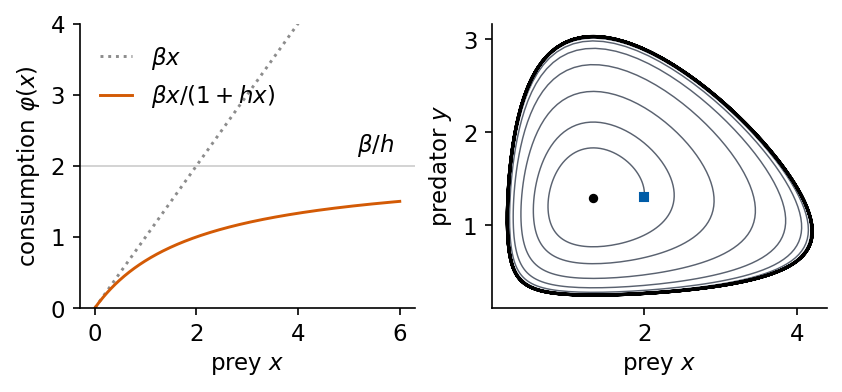

In [6]:
with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(1, 2, figsize=(5.5, 2.5), layout="constrained")
    xx = np.linspace(0, 6, 300)
    axs[0].plot(xx, BETA * xx, color="0.55", ls=":", label=r"$\beta x$")
    axs[0].plot(xx, BETA * xx / (1 + H_SAT * xx), color=PRED, label=r"$\beta x/(1+hx)$")
    axs[0].axhline(BETA / H_SAT, color="0.8", lw=0.8)
    axs[0].text(5.9, BETA / H_SAT + 0.1, r"$\beta/h$", ha="right", va="bottom")
    axs[0].set_xlabel("prey $x$"); axs[0].set_ylabel(r"consumption $\varphi(x)$"); axs[0].set_ylim(0, 4)
    axs[0].legend(loc="upper left", handlelength=1.4)
    axs[1].plot(true[:, 0], true[:, 1], color=UJGray, lw=0.7)
    late = t_grid >= 150
    axs[1].plot(true[late, 0], true[late, 1], color="k", lw=1.5)
    axs[1].plot(xs_rm, ys_rm, "o", color="k", ms=3.5); axs[1].plot(*np.asarray(S0_TRUE), "s", color=PREY, ms=3.5)
    axs[1].set_xlabel("prey $x$"); axs[1].set_ylabel("predator $y$")
    save(fig, "fig_lab044_holling_limit_cycle"); plt.show()

<hr/>
## 2. Noisy population counts

Population counts carry an error proportional to the population, so we use multiplicative noise. The two populations are recorded every $\Delta t=0.1$ for $0\le t\le40$, about three periods of the oscillation,
$$\tilde x_k=x(t_k)\,e^{\sigma\xi_k},\qquad \tilde y_k=y(t_k)\,e^{\sigma\eta_k},\qquad \sigma=0.05,\qquad k=0,\dots,400,$$
with independent standard normal $\xi_k,\eta_k$, a relative error of about 5 per cent. During the measured window the oscillation is still growing towards the limit cycle, so the data cover only the inner part of the region that the populations visit later. The noise-free trajectory up to $t=200$ is kept for testing.

401 measured states | prey range in the window [0.29, 3.45], on the limit cycle [0.21, 4.20]


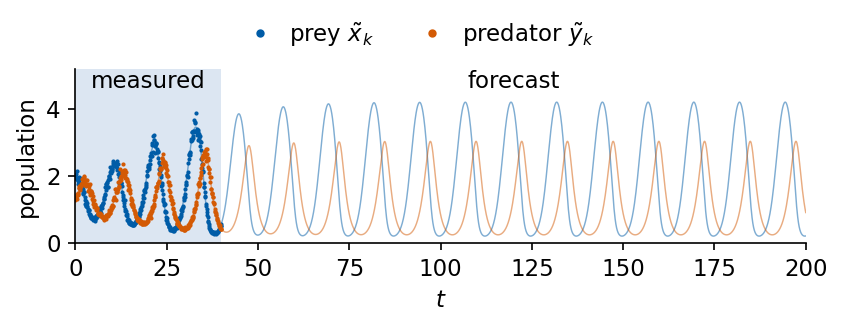

In [7]:
SIGMA = 0.05
rng = np.random.default_rng(0)
def measure(S, rng):
    return S * np.exp(SIGMA * rng.normal(size=S.shape))
data = measure(true[:N_TRAIN + 1], rng)
t_data = t_grid[:N_TRAIN + 1]
print(f"{len(data)} measured states | prey range in the window [{true[:N_TRAIN + 1, 0].min():.2f}, "
      f"{true[:N_TRAIN + 1, 0].max():.2f}], on the limit cycle [{cyc_true['x_min']:.2f}, {cyc_true['x_max']:.2f}]")
nums["n_data"] = len(data); nums["x_max_train"] = float(true[:N_TRAIN + 1, 0].max())

with mpl.rc_context(SLIDE_RC):
    fig, ax = plt.subplots(figsize=(5.5, 2.1), layout="constrained")
    ax.axvspan(0, T_TRAIN, color="#DCE6F2", lw=0, zorder=0)
    ax.text(T_TRAIN / 2, 5.15, "measured", ha="center", va="top")
    ax.text((T_TRAIN + T_END) / 2, 5.15, "forecast", ha="center", va="top")
    ax.plot(t_grid, true[:, 0], color=PREY, lw=0.7, alpha=0.5); ax.plot(t_grid, true[:, 1], color=PRED, lw=0.7, alpha=0.5)
    ax.plot(t_data, data[:, 0], ".", color=PREY, ms=2, label=r"prey $\tilde x_k$")
    ax.plot(t_data, data[:, 1], ".", color=PRED, ms=2, label=r"predator $\tilde y_k$")
    ax.set_xlim(0, T_END); ax.set_ylim(0, 5.2); ax.set_xlabel("$t$"); ax.set_ylabel("population")
    fig.legend(*ax.get_legend_handles_labels(), loc="outside upper center", ncol=2, handlelength=1.0, markerscale=3)
    save(fig, "fig_lab044_data"); plt.show()

<hr/>
## 3. Three models

The **Lotka–Volterra fit** keeps the textbook form and fits the four rates $(\alpha,\beta,\gamma,\delta)$, parametrised by their logarithms so that they stay positive. It cannot produce a limit cycle.

The **neural ODE** represents the whole vector field by a network, $\dot{\mathbf s}=\mathbf N_\phi(\mathbf s)$ with $\mathbf s=(x,y)$.

The **hybrid** model keeps the single-species terms with the rates $\alpha=1$ and $\delta=0.8$, which we assume known from separate experiments, and learns the rest,
$$\dot x=\alpha x+U_1(x,y),\qquad \dot y=-\delta y+U_2(x,y).$$
The network $\mathbf U_\theta=(U_1,U_2)$ has to represent the interaction and the self-limitation of the prey, whose true form is
$$U_1=-\frac{\alpha}{K}x^2-\frac{\beta xy}{1+hx},\qquad U_2=\frac{\gamma xy}{1+hx}.$$
Both networks are multilayer perceptrons with two inputs, two hidden layers of 32 tanh units and two linear outputs. The inputs are divided by 2, so that they are of order one. The weights start from a normal distribution of variance $1/n_{\rm in}$ and the biases from zero, and the last layer of $\mathbf U_\theta$ is scaled by 0.1, so that the hybrid model starts close to two uncoupled species.

In [8]:
def init_mlp(key, sizes, last_scale=1.0):
    # list of (W, b) for the layer widths `sizes`; W ~ N(0, 1/n_in), b = 0, last layer scaled by last_scale
    params = []
    for i, (n_in, n_out) in enumerate(zip(sizes[:-1], sizes[1:])):
        key, k = jax.random.split(key)
        W = jax.random.normal(k, (n_in, n_out)) / np.sqrt(n_in)
        params.append((W * (last_scale if i == len(sizes) - 2 else 1.0), jnp.zeros(n_out)))
    return params

def mlp(params, x):
    for W, b in params[:-1]:
        x = jnp.tanh(x @ W + b)
    W, b = params[-1]
    return x @ W + b

def n_params(params):
    return int(sum(p.size for p in jax.tree.leaves(params)))

X_SCALE = 2.0
SIZES = [2, 32, 32, 2]

def f_lv_fit(logp):
    a, b, g, d = jnp.exp(logp)
    return lotka_volterra(a, b, g, d)

def f_neural(params):
    return lambda s, t: mlp(params, s / X_SCALE)

def f_hybrid(params):
    return lambda s, t: jnp.array([ALPHA * s[0], -DELTA * s[1]]) + mlp(params, s / X_SCALE)

print("parameters of N_phi and U_theta:", n_params(init_mlp(jax.random.PRNGKey(0), SIZES)))
nums["n_params"] = n_params(init_mlp(jax.random.PRNGKey(0), SIZES))

parameters of N_phi and U_theta: 1218


The drawing shows the hybrid model as nodes and edges. The network reads the two populations and returns $U_1$ and $U_2$, which are added to the known terms $\alpha x$ and $-\delta y$. The sums form the vector field $\mathbf f=(\dot x,\dot y)$ that one RK4 step integrates from $t$ to $t+h$, and the new state is fed back as the next input. The function `draw_layers` draws a fully connected network as columns of nodes, every node joined to every node of the next column, with dots marking columns that hold more units than drawn.

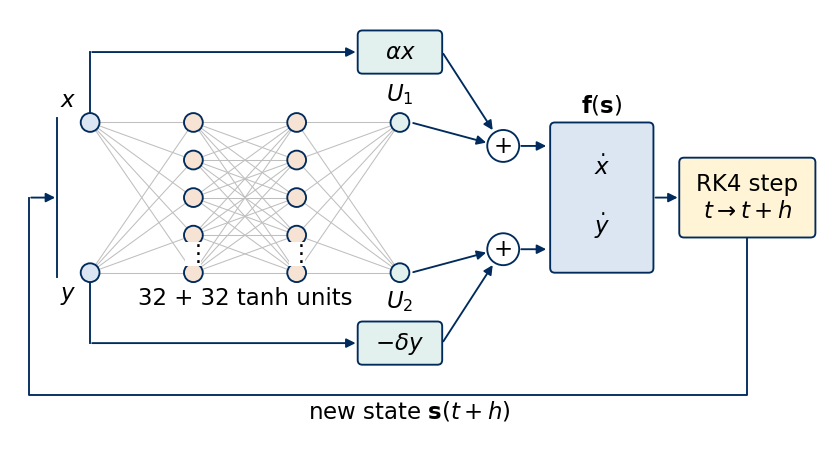

In [9]:
def draw_layers(ax, sizes, xs, ys_span=1.6, node_r=0.1, colors=None, y0=0.0, edge_color="0.75"):
    """Nodes-and-edges drawing of a fully connected network.

    sizes[i] nodes are placed in a vertical column at x = xs[i], centred at height y0; every node of a
    column is joined to every node of the next column (a dense layer).
    Returns the node coordinates, one list of (x, y) per column, for arrows and labels.
    """
    cols = []
    for n, x in zip(sizes, xs):
        ys = y0 + (np.linspace(ys_span / 2, -ys_span / 2, n) if n > 1 else np.array([0.0]))
        cols.append([(x, y) for y in ys])
    for a, b in zip(cols[:-1], cols[1:]):            # edges first, so that the nodes are drawn on top
        for (xa, ya) in a:
            for (xb, yb) in b:
                ax.plot([xa, xb], [ya, yb], color=edge_color, lw=0.5, zorder=1)
    for i, col in enumerate(cols):                    # nodes as circles, one fill colour per column
        for (x, y) in col:
            ax.add_patch(Circle((x, y), node_r, fc=(colors[i] if colors else "#DCE6F2"), ec=UJNavy, lw=0.9, zorder=3))
    return cols

def box(ax, x, y, w, h, text, fc="#F6E3D3"):
    # rounded rectangle centred at (x, y) with a label
    ax.add_patch(FancyBboxPatch((x - w / 2, y - h / 2), w, h, boxstyle="round,pad=0.05", fc=fc, ec=UJNavy, lw=0.9, zorder=3))
    ax.text(x, y, text, ha="center", va="center", zorder=4)

def arrow(ax, p, q):
    ax.add_patch(FancyArrowPatch(p, q, arrowstyle="-|>", mutation_scale=9, color=UJNavy, lw=0.9, zorder=2,
                                 shrinkA=1, shrinkB=1))

def dots(ax, col):
    # vertical dots between the last two drawn nodes of a wide column
    ax.text(col[0][0], 0.5 * (col[-2][1] + col[-1][1]), r"$\vdots$", ha="center", va="center", zorder=4,
            bbox=dict(fc="white", ec="none", pad=0.3))

with mpl.rc_context(SLIDE_RC):
    fig, ax = plt.subplots(figsize=(5.5, 2.9), layout="constrained")
    cols = draw_layers(ax, [2, 5, 5, 2], xs=[0.6, 1.7, 2.8, 3.9], colors=["#DCE6F2", "#F6E3D3", "#F6E3D3", "#E3F1EE"])
    dots(ax, cols[1]); dots(ax, cols[2])
    ax.text(0.45, cols[0][0][1] + 0.12, "$x$", ha="right", va="bottom"); ax.text(0.45, cols[0][1][1] - 0.12, "$y$", ha="right", va="top")
    ax.text(3.9, cols[3][0][1] + 0.17, "$U_1$", ha="center", va="bottom"); ax.text(3.9, cols[3][1][1] - 0.17, "$U_2$", ha="center", va="top")
    ax.text(2.25, -0.95, "32 + 32 tanh units", ha="center", va="top")
    # known single-species terms above and below the network, fed directly by x and y
    box(ax, 3.9, 1.55, 0.8, 0.36, r"$\alpha x$", fc="#E3F1EE"); box(ax, 3.9, -1.55, 0.8, 0.36, r"$-\delta y$", fc="#E3F1EE")
    ax.plot([0.6, 0.6], [0.9, 1.55], color=UJNavy, lw=0.9, zorder=2); arrow(ax, (0.6, 1.55), (3.45, 1.55))
    ax.plot([0.6, 0.6], [-0.9, -1.55], color=UJNavy, lw=0.9, zorder=2); arrow(ax, (0.6, -1.55), (3.45, -1.55))
    for yy, sign in ((0.55, 1), (-0.55, -1)):          # the two summation nodes
        ax.add_patch(Circle((5.0, yy), 0.17, fc="white", ec=UJNavy, lw=0.9, zorder=3))
        ax.text(5.0, yy, "+", ha="center", va="center", zorder=4)
        arrow(ax, (4.02, sign * 0.8), (4.84, yy + sign * 0.03))
        arrow(ax, (4.35, sign * 1.55), (4.9, yy + sign * 0.15))
        arrow(ax, (5.17, yy), (5.48, yy))
    box(ax, 6.05, 0.0, 1.0, 1.5, r"$\dot x$" + "\n\n" + r"$\dot y$", fc="#DCE6F2")
    ax.text(6.05, 0.86, r"$\mathbf{f}(\mathbf{s})$", ha="center", va="bottom")
    box(ax, 7.6, 0.0, 1.35, 0.75, "RK4 step\n" + r"$t\to t+h$", fc="#FFF4D6")
    arrow(ax, (6.6, 0.0), (6.88, 0.0))
    y_low = -2.1                                    # feedback of the new state to the input layer
    ax.plot([7.6, 7.6, -0.05, -0.05], [-0.42, y_low, y_low, 0.0], color=UJNavy, lw=0.9, zorder=2)
    ax.plot([0.25, 0.25], [-0.85, 0.85], color=UJNavy, lw=0.9, zorder=2)      # the input layer receives (x, y)
    arrow(ax, (-0.05, 0.0), (0.25, 0.0))
    ax.text(4.0, y_low - 0.05, r"new state $\mathbf{s}(t+h)$", ha="center", va="top")
    ax.set_xlim(-0.2, 8.4); ax.set_ylim(-2.55, 1.95); ax.set_aspect("equal"); ax.axis("off")
    save(fig, "fig_lab044_hybrid_architecture"); plt.show()

<hr/>
## 4. Training through the solver

We use the multiple-shooting loss. Every measured state $\tilde{\mathbf s}_k$ with $k=0,\dots,380$ starts a segment that the model integrates by RK4 over $H=20$ steps of $\Delta t$, two time units, and the loss compares the integrated states with the measured ones,
$$\mathcal L=\frac{1}{2\,n_{\rm seg}(H+1)}\sum_{k}\sum_{j=0}^{H}\sum_{i=1}^{2}\left(\frac{\hat s_i(t_{k+j};\tilde{\mathbf s}_k)-\tilde s_{i,k+j}}{\varsigma_i}\right)^2,\qquad n_{\rm seg}=381,$$
where $\varsigma_i$ is the standard deviation of component $i$ over the data, which puts both species on the same scale. Each segment starts at its own time $t_k$, which matters once the vector field depends on time in the last section. The gradient comes from `jax.grad` through the RK4 steps, and Adam [D. P. Kingma, J. Ba, [arXiv:1412.6980](https://arxiv.org/abs/1412.6980)] updates the parameters 3000 times with a cosine-decaying learning rate. Before training we compare the directional derivative of the loss along a random unit direction $\mathbf v$ in weight space with the central difference $[\mathcal L(\mathbf w+\epsilon\mathbf v)-\mathcal L(\mathbf w-\epsilon\mathbf v)]/(2\epsilon)$, $\epsilon=10^{-4}$, of the same loss integrated by the adaptive `Tsit5` solver of `diffrax` [Ch. Tsitouras, Comput. Math. Appl. **62**, 770 (2011), [doi:10.1016/j.camwa.2011.06.002](https://doi.org/10.1016/j.camwa.2011.06.002)] with tolerances $10^{-12}$.

In [10]:
H_SEG = 20
starts = np.arange(0, N_TRAIN - H_SEG + 1)                  # k = 0, ..., 380
idx = starts[:, None] + np.arange(H_SEG + 1)[None, :]

def segment_loss(f_maker, data, solver="rk4", t_first=0.0):
    # multiple-shooting loss; every measured state starts a segment of H_SEG steps at its own time t_k
    S0, target = jnp.asarray(data[starts]), jnp.asarray(data[idx])
    T0, scale = jnp.asarray(t_first + starts * DT), jnp.asarray(data.std(0))
    def loss(params):
        f = f_maker(params)
        if solver == "rk4":
            traj = jax.vmap(lambda s, t0: rk4_solve(f, s, t0, H_SEG, DT))(S0, T0)
        else:   # adaptive Tsit5 of diffrax for an autonomous field, all segments as one batched state
            ys = diffrax_solve(lambda S, t: jax.vmap(lambda s: f(s, t))(S), S0, jnp.arange(H_SEG + 1) * DT,
                               solver=diffrax.Tsit5(), tol=1e-12)
            traj = jnp.swapaxes(ys, 0, 1)
        return jnp.mean(((traj - target) / scale) ** 2)
    return loss

# directional derivative of the hybrid loss along a random unit direction v of the weights
p_test = init_mlp(jax.random.PRNGKey(3), SIZES)
leaves, treedef = jax.tree.flatten(p_test)
v = [jax.random.normal(jax.random.PRNGKey(10 + i), x.shape) for i, x in enumerate(leaves)]
v_norm = np.sqrt(sum(float(jnp.sum(x ** 2)) for x in v))
v = jax.tree.unflatten(treedef, [x / v_norm for x in v])
shift = lambda p, a: jax.tree.map(lambda x, y: x + a * y, p, v)
L_tsit = jax.jit(segment_loss(f_hybrid, data, solver="diffrax"))
d_ref = (float(L_tsit(shift(p_test, 1e-4))) - float(L_tsit(shift(p_test, -1e-4)))) / 2e-4
g = jax.grad(segment_loss(f_hybrid, data))(p_test)
d_rk4 = float(sum(jnp.sum(a * b) for a, b in zip(jax.tree.leaves(g), jax.tree.leaves(v))))
print(f"jax.grad . v = {d_rk4:.8e} | Tsit5 central difference = {d_ref:.8e} | relative difference {abs(d_rk4 - d_ref) / abs(d_ref):.1e}")
nums["grad_rel_diff"] = abs(d_rk4 - d_ref) / abs(d_ref)

jax.grad . v = 1.64774600e+00 | Tsit5 central difference = 1.64775230e+00 | relative difference 3.8e-06


In [11]:
N_STEPS = 3000

def train(f_maker, params, data, n_steps=N_STEPS, lr=3e-3, t_first=0.0):
    # Adam on the multiple-shooting loss; the data start at time t_first
    loss = segment_loss(f_maker, data, t_first=t_first)
    tx = optax.adam(optax.cosine_decay_schedule(lr, n_steps, alpha=0.05))
    opt_state = tx.init(params)
    @jax.jit
    def update(params, opt_state):
        l, g = jax.value_and_grad(loss)(params)
        u, opt_state = tx.update(g, opt_state, params)
        return optax.apply_updates(params, u), opt_state, l
    hist = np.empty(n_steps)
    for i in range(n_steps):
        params, opt_state, l = update(params, opt_state)
        hist[i] = l
    return params, hist, float(loss(params))

fits = {}
for name, f_maker, p0, n, lr in (
        ("Lotka-Volterra fit", f_lv_fit, jnp.zeros(4), 1500, 2e-2),
        ("neural ODE", f_neural, init_mlp(jax.random.PRNGKey(0), SIZES), N_STEPS, 3e-3),
        ("hybrid", f_hybrid, init_mlp(jax.random.PRNGKey(0), SIZES, last_scale=0.1), N_STEPS, 3e-3)):
    t0 = time.time()
    p, hist, l_end = train(f_maker, p0, data, n_steps=n, lr=lr)
    fits[name] = dict(params=p, hist=hist, loss=l_end, time=time.time() - t0, f=f_maker(p))
    print(f"{name:18s} loss {hist[0]:.3e} -> {l_end:.3e}   ({fits[name]['time']:.0f} s)")
    nums[f"loss_{name}"] = l_end
rates = np.exp(np.asarray(fits["Lotka-Volterra fit"]["params"]))
print("fitted Lotka-Volterra rates (alpha, beta, gamma, delta):", np.round(rates, 3))
nums["lv_rates"] = rates.tolist()
noise_floor = np.mean((true[:N_TRAIN + 1] - data) ** 2 / data.std(0) ** 2)
print(f"noise contribution sum_i <(s_true - s_meas)^2 / var_i> / 2 = {noise_floor:.3e}")
nums["noise_floor"] = float(noise_floor)

Lotka-Volterra fit loss 8.815e-01 -> 4.017e-02   (2 s)


neural ODE         loss 6.124e-01 -> 2.034e-02   (60 s)


hybrid             loss 1.961e+01 -> 2.105e-02   (61 s)
fitted Lotka-Volterra rates (alpha, beta, gamma, delta): [0.648 0.509 0.306 0.473]
noise contribution sum_i <(s_true - s_meas)^2 / var_i> / 2 = 1.119e-02


The directional derivatives agree to a relative difference of $3.8\times10^{-6}$, the size of the RK4 discretisation error, so `jax.grad` through our integrator gives the correct gradient. After training the Lotka–Volterra fit ends at $\mathcal L=4.0\times10^{-2}$, while the neural ODE and the hybrid model reach $2.0\times10^{-2}$ and $2.1\times10^{-2}$. The noise of the measured states alone contributes $1.1\times10^{-2}$, and the noise of the initial state of each segment, propagated along the segment, adds to this, so both networks fit the data close to the level the noise permits. The fitted Lotka–Volterra rates, $\alpha=0.648$, $\beta=0.509$, $\gamma=0.306$ and $\delta=0.473$, differ strongly from the single-species values $\alpha=1$ and $\delta=0.8$. A model without saturation and self-limitation can follow a growing oscillation only by distorting all four rates.

<hr/>
## 5. Learned interaction

The network was trained only through the trajectories it produces, and nothing forced its two outputs to equal the true $U_1$ and $U_2$. The left panels of the figure compare $U_1$ and $U_2$ of the trained network along the measured trajectory, evaluated at the noisy states $\tilde{\mathbf s}_k$, with the true functions evaluated at the same states. The right panel shows where in the phase plane the network can be trusted. Its colour gives the relative error $|U_2-U_2^{\rm true}|/\max|U_2^{\rm true}|$ on a grid, with the maximum taken over the limit cycle. The true trajectory during the measured window, in orange, and the limit cycle, in blue, are drawn on top.

on the measured states: rms(U - U_true) / rms(U_true) = 0.015 (U_1), 0.022 (U_2)


largest relative error of U_2 on the limit cycle: 0.08


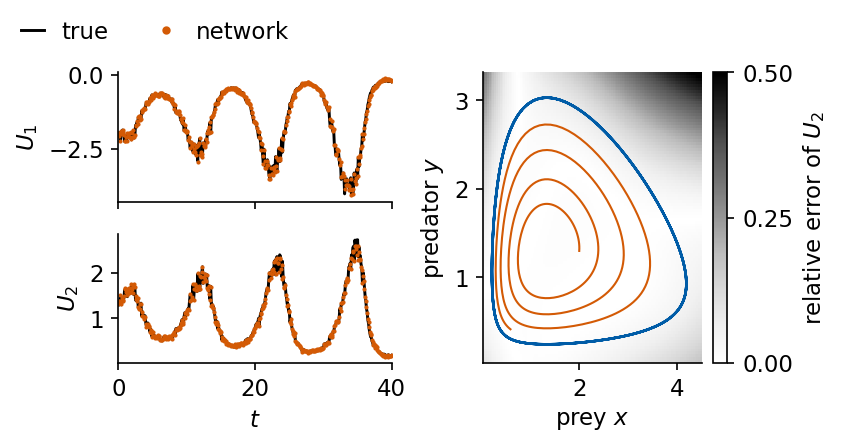

In [12]:
p_h = fits["hybrid"]["params"]
U_net = lambda S: np.asarray(mlp(p_h, jnp.asarray(S) / X_SCALE))
U_data, U_ref = U_net(data), U_true(data)
rel = np.sqrt(np.mean((U_data - U_ref) ** 2, 0) / np.mean(U_ref ** 2, 0))
print(f"on the measured states: rms(U - U_true) / rms(U_true) = {rel[0]:.3f} (U_1), {rel[1]:.3f} (U_2)")
nums["U_rel_err"] = rel.tolist()

xg, yg = np.meshgrid(np.linspace(0.05, 4.5, 120), np.linspace(0.05, 3.3, 100))
G = np.stack([xg.ravel(), yg.ravel()], 1)
late = t_grid >= 150
err_map = np.abs(U_net(G)[:, 1] - U_true(G)[:, 1]).reshape(xg.shape) / np.abs(U_true(true[late])[:, 1]).max()
on_cycle = np.abs(U_net(true[late])[:, 1] - U_true(true[late])[:, 1]).max() / np.abs(U_true(true[late])[:, 1]).max()
print(f"largest relative error of U_2 on the limit cycle: {on_cycle:.2f}")
nums["U2_err_on_cycle"] = float(on_cycle)

with mpl.rc_context(SLIDE_RC):
    fig = plt.figure(figsize=(5.5, 2.9), layout="constrained")
    gs = fig.add_gridspec(2, 2, width_ratios=[1.25, 1])
    for j in range(2):
        ax = fig.add_subplot(gs[j, 0])
        ax.plot(t_data, U_ref[:, j], color="k", lw=1.4, label="true")
        ax.plot(t_data, U_data[:, j], ".", color=DSOrange, ms=2, label="network")
        ax.set_ylabel(f"$U_{j + 1}$"); ax.set_xlim(0, T_TRAIN)
        if j == 0: ax.set_xticklabels([]); fig.legend(*ax.get_legend_handles_labels(), loc="outside upper left", ncol=2, handlelength=1.0, markerscale=3)
        else: ax.set_xlabel("$t$")
    ax = fig.add_subplot(gs[:, 1])
    im = ax.pcolormesh(xg, yg, err_map, cmap="Greys", vmin=0, vmax=0.5, shading="auto")
    ax.plot(true[:N_TRAIN + 1, 0], true[:N_TRAIN + 1, 1], color=DSOrange, lw=1.0)
    ax.plot(true[late, 0], true[late, 1], color=UJBlue, lw=1.2)
    fig.colorbar(im, ax=ax, label="relative error of $U_2$", ticks=[0, 0.25, 0.5])
    ax.set_xlabel("prey $x$"); ax.set_ylabel("predator $y$")
    save(fig, "fig_lab044_learned_interaction"); plt.show()

Along the measured trajectory the network reproduces both functions closely, with a root-mean-square deviation of 1.5 per cent of the root-mean-square $U_1$ and 2.2 per cent for $U_2$. The error map shows that this accuracy holds inside the region swept by the data and deteriorates far from it, in the upper right corner, which no trajectory visits. The limit cycle extends beyond the measured spiral, and on the cycle the largest error of $U_2$ is 8 per cent of its maximum.

### Sparse regression with a polynomial library

The first attempt at a formula uses the library of all monomials of degree one to three,
$$\Theta_{\rm poly}=\{x,\ y,\ x^2,\ xy,\ y^2,\ x^3,\ x^2y,\ xy^2,\ y^3\},$$
and sequentially thresholded least squares (STLSQ) for each output $U_j(\tilde{\mathbf s}_k)\approx\sum_m\xi_{jm}\Theta_m(\tilde{\mathbf s}_k)$. Every column is divided by its root mean square over the data, a least-squares solve gives the scaled coefficients, those with modulus below the threshold $\lambda$ are set to zero, and the solve is repeated on the remaining columns until the set of active terms stops changing. We use $\lambda=0.2\,{\rm rms}(U_j)$ and, for comparison, the smaller $\lambda=0.05\,{\rm rms}(U_j)$. The relative residual ${\rm rms}(U_j-\Theta\boldsymbol\xi_j)/{\rm rms}(U_j)$ measures how well a formula reproduces the network on the data.

In [13]:
def stlsq(Theta, y, lam, max_iter=20):
    # sequentially thresholded least squares on RMS-scaled columns; coefficients of the unscaled columns
    scale = np.sqrt(np.mean(Theta ** 2, 0))
    A = Theta / scale
    xi = np.linalg.lstsq(A, y, rcond=None)[0]
    active = np.ones(len(xi), bool)
    for _ in range(max_iter):
        new = active & (np.abs(xi) >= lam)
        xi = np.zeros_like(xi)
        if new.any():
            xi[new] = np.linalg.lstsq(A[:, new], y, rcond=None)[0]
        if np.array_equal(new, active):
            break
        active = new
    return xi / scale

POLY_NAMES = ["x", "y", "x^2", "xy", "y^2", "x^3", "x^2y", "xy^2", "y^3"]
def poly_library(S, xp=np):
    x, y = S[:, 0], S[:, 1]
    return xp.stack([x, y, x ** 2, x * y, y ** 2, x ** 3, x ** 2 * y, x * y ** 2, y ** 3], 1)

def formula(xi, names):
    return " ".join(f"{v:+.3f} {n}" for v, n in zip(xi, names) if v != 0) or "0"

def sparse_fit(Theta, U, lam_rel):
    xis = np.stack([stlsq(Theta, U[:, j], lam_rel * np.sqrt(np.mean(U[:, j] ** 2))) for j in range(U.shape[1])])
    res = [float(np.sqrt(np.mean((U[:, j] - Theta @ xis[j]) ** 2) / np.mean(U[:, j] ** 2))) for j in range(U.shape[1])]
    return xis, res

Th_poly = poly_library(data)
poly_fits = {}
for lam_rel in (0.05, 0.2):
    xis, res = sparse_fit(Th_poly, U_data, lam_rel)
    poly_fits[lam_rel] = xis
    for j in range(2):
        print(f"lambda = {lam_rel:4.2f} rms(U):  U_{j + 1} = {formula(xis[j], POLY_NAMES):58s} relative residual {res[j]:.3f}")
    nums[f"poly_res_{lam_rel}"] = res
    nums[f"poly_terms_{lam_rel}"] = [int((x != 0).sum()) for x in xis]

lambda = 0.05 rms(U):  U_1 = -0.097 x -0.087 x^2 -0.662 xy -0.068 y^2 -0.009 x^3 +0.057 x^2y +0.052 xy^2 relative residual 0.011
lambda = 0.05 rms(U):  U_2 = +0.173 x -0.095 y -0.145 x^2 +0.736 xy +0.132 y^2 +0.028 x^3 -0.093 x^2y -0.041 xy^2 -0.023 y^3 relative residual 0.011
lambda = 0.20 rms(U):  U_1 = -0.733 xy                                                  relative residual 0.149
lambda = 0.20 rms(U):  U_2 = +0.180 x -0.168 x^2 +0.754 xy +0.039 x^3 -0.126 x^2y       relative residual 0.025


With the small threshold both outputs keep seven and nine of the nine monomials, with a residual of 1.1 per cent. Such a formula reproduces the network on the data, but its many terms of alternating sign carry no physical meaning. With the larger threshold the prey output reduces to $U_1=-0.733\,xy$, a Lotka–Volterra encounter term with a residual of 15 per cent, while the predator output keeps five terms, $0.180x-0.168x^2+0.754xy+0.039x^3-0.126x^2y$. The negative $x^2y$ term is the first correction of the expansion $xy/(1+hx)=xy-hx^2y+h^2x^3y-\dots$, so the regression approximates the saturation by a truncated Taylor series, which is accurate only for $hx\ll1$, while the data reach $hx\approx1.7$.

### Rational terms

A library is linear in the coefficients $\xi$, so a parameter inside a nonlinearity, here the saturation constant $h$ in the denominator, cannot be a coefficient. One option is to add columns $xy/(1+h_mx)$ for a grid of values $h_m$. These columns are almost proportional to each other over the measured range, and the regression then distributes the interaction over several of them with large coefficients of opposite sign. To see how strongly the data determine $h$, we scan it. For each $h$ we add the single column $R_h=xy/(1+hx)$ to the five monomials of degree up to two and record the sum of the relative residuals of $U_1$ and $U_2$ after STLSQ with $\lambda=0.2\,{\rm rms}(U_j)$.

In [14]:
def rational_library(S, h, xp=np):
    x, y = S[:, 0], S[:, 1]
    return xp.stack([x, y, x ** 2, x * y, y ** 2, x * y / (1 + h * x)], 1)
RAT_NAMES = ["x", "y", "x^2", "xy", "y^2", "R_h"]

# a grid of rational columns in one library
GRID_H = (0.25, 0.5, 1.0, 2.0)
Th_grid = np.concatenate([poly_library(data)[:, :5]] + [(data[:, 0] * data[:, 1] / (1 + hm * data[:, 0]))[:, None] for hm in GRID_H], 1)
xis, res = sparse_fit(Th_grid, U_data, 0.2)
names_grid = POLY_NAMES[:5] + [f"xy/(1+{hm:g}x)" for hm in GRID_H]
for j in range(2):
    print(f"grid of h, U_{j + 1} = {formula(xis[j], names_grid)}   residual {res[j]:.3f}")

h_scan = np.round(np.arange(0.0, 2.01, 0.05), 2)
scan_res = np.array([sum(sparse_fit(rational_library(data, h), U_data, 0.2)[1]) for h in h_scan])
h_best = float(h_scan[np.argmin(scan_res)])
near = h_scan[scan_res < 1.1 * scan_res.min()]
print(f"scan: smallest summed residual {scan_res.min():.4f} at h = {h_best}, "
      f"within 10 per cent of it for {near.min():.2f} <= h <= {near.max():.2f}")
nums["h_scan_best"] = h_best; nums["h_scan_lo"], nums["h_scan_hi"] = float(near.min()), float(near.max())

grid of h, U_1 = -0.382 y -0.164 x^2 +1.611 xy -19.990 xy/(1+0.25x) +46.365 xy/(1+0.5x) -50.783 xy/(1+1x) +25.759 xy/(1+2x)   residual 0.012
grid of h, U_2 = -0.424 y +1.059 xy -14.536 xy/(1+0.25x) +38.407 xy/(1+0.5x) -44.678 xy/(1+1x) +25.152 xy/(1+2x)   residual 0.020
scan: smallest summed residual 0.0361 at h = 0.5, within 10 per cent of it for 0.45 <= h <= 0.50


The library with the four columns $xy/(1+h_mx)$, $h_m\in\{0.25,0.5,1,2\}$, reproduces the network with residuals of 1.2 and 2.0 per cent, but with coefficients between $-51$ and $+46$ that cancel each other, so it cannot be read as a law. The scan over $h$ is more informative. The summed residual has its smallest value 0.036 at $h=0.5$ and stays within 10 per cent of it only for $0.45\le h\le0.5$. The curve is not smooth, because STLSQ selects a different set of terms at different $h$, and values near 0.042 also occur for $h$ above 1, where the regression compensates the stronger saturation with additional monomials. The data therefore favour the true saturation constant, but a scan alone gives a rough estimate.

A rational function with an unknown denominator can still be found by linear regression after multiplying the equation by the denominator. For the predator equation the identity $(1+hx)\,U_2=\gamma xy$ is linear in both unknowns,
$$U_2=\gamma\,xy-h\,\big(x\,U_2\big),$$
so the product $x\,U_2$ of the learned output and the prey becomes an extra library column whose coefficient is $-h$. Rewriting rational dynamics in such an implicit form is the idea of the implicit extension of SINDy [N. M. Mangan, S. L. Brunton, J. L. Proctor, J. N. Kutz, IEEE Trans. Mol. Biol. Multi-Scale Commun. **2**, 52 (2016), [doi:10.1109/TMBMC.2016.2633265](https://doi.org/10.1109/TMBMC.2016.2633265)]. Least squares on the two columns $xy$ and $xU_2$ gives $\hat\gamma$ and $\hat h$. With $\hat h$ fixed, STLSQ on the library $\{x,y,x^2,xy,y^2,R_{\hat h}\}$ then selects the terms of both outputs.

implicit regression of U_2: gamma = 0.969 (true 1.0), h = 0.474 (true 0.5)
h = 0.474:  U_1 = -0.165 x^2 -0.973 R_h                    relative residual 0.014
h = 0.474:  U_2 = +0.970 R_h                               relative residual 0.022
true:       U_1 = -0.167 x^2 -1.000 R_h,  U_2 = +1.000 R_h  with h = 0.5


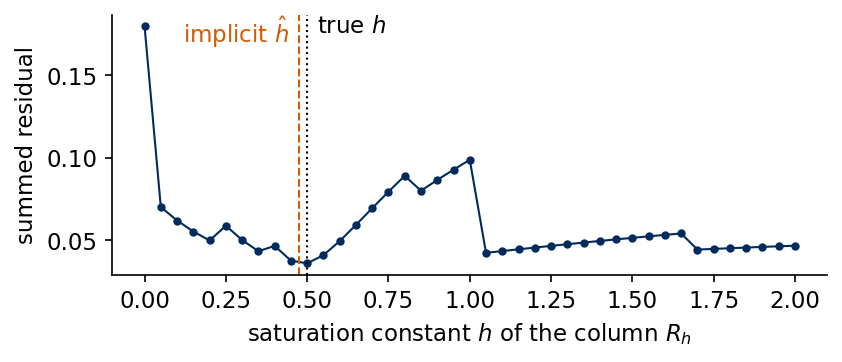

In [15]:
x_d, y_d = data[:, 0], data[:, 1]
A_imp = np.stack([x_d * y_d, -x_d * U_data[:, 1]], 1)
gamma_hat, h_hat = np.linalg.lstsq(A_imp, U_data[:, 1], rcond=None)[0]
print(f"implicit regression of U_2: gamma = {gamma_hat:.3f} (true {GAMMA}), h = {h_hat:.3f} (true {H_SAT})")
xi_rat, res_rat = sparse_fit(rational_library(data, h_hat), U_data, 0.2)
for j in range(2):
    print(f"h = {h_hat:.3f}:  U_{j + 1} = {formula(xi_rat[j], RAT_NAMES):40s} relative residual {res_rat[j]:.3f}")
print(f"true:       U_1 = {-ALPHA / K_CAP:+.3f} x^2 {-BETA:+.3f} R_h,  U_2 = {GAMMA:+.3f} R_h  with h = {H_SAT}")
nums["gamma_hat"], nums["h_hat"] = float(gamma_hat), float(h_hat)
nums["xi_rat"] = xi_rat.tolist(); nums["res_rat"] = res_rat

with mpl.rc_context(SLIDE_RC):
    fig, ax = plt.subplots(figsize=(5.5, 2.3), layout="constrained")
    ax.plot(h_scan, scan_res, "o-", color=UJNavy, ms=3, lw=1.0)
    ax.axvline(H_SAT, color="k", lw=1.0, ls=":"); ax.axvline(h_hat, color=DSOrange, lw=1.0, ls="--")
    y_top = ax.get_ylim()[1]
    ax.text(H_SAT + 0.03, y_top, "true $h$", va="top", ha="left")
    ax.text(h_hat - 0.03, y_top, r"implicit $\hat h$", va="top", ha="right", color=DSOrange)
    ax.set_xlabel("saturation constant $h$ of the column $R_h$"); ax.set_ylabel("summed residual")
    save(fig, "fig_lab044_h_scan"); plt.show()

The implicit regression gives $\hat\gamma=0.969$ and $\hat h=0.474$, 3 and 5 per cent below the true values. With $R_{\hat h}$ in the library, STLSQ selects exactly the terms of the true model, $U_1=-0.165\,x^2-0.973\,R_{\hat h}$ and $U_2=0.970\,R_{\hat h}$, against the true $-0.167\,x^2-R_h$ and $R_h$. The residuals of 1.4 and 2.2 per cent are as small as those of the long polynomial formulas, with two terms in place of seven or more. The figure shows the scan together with the implicit estimate.

### Refit of the formula through the solver

The regression fitted the formula to the network output, and the small errors of the network, for example the bias of $\hat h$, pass into the coefficients. The formula has only four free numbers, the three active coefficients and $h$, so we can refit them directly to the measured populations with the same multiple-shooting loss, starting from the regression values. This is cheap, and the regression has already fixed the form of the equation.

In [16]:
def f_formula(xis, lib):
    # hybrid model with a recovered formula: known terms + library @ coefficients
    xis = jnp.asarray(xis)
    return lambda s, t: jnp.array([ALPHA * s[0], -DELTA * s[1]]) + lib(s[None], jnp)[0] @ xis.T

mask = jnp.asarray(xi_rat != 0, dtype=float)            # keep the terms selected by STLSQ
def f_rational(params):
    xis, log_h = params
    return f_formula(xis * mask, lambda S, xp: rational_library(S, jnp.exp(log_h), xp))
t0 = time.time()
p_ref, hist_ref, l_ref = train(f_rational, (jnp.asarray(xi_rat), jnp.log(h_hat)), data, n_steps=800, lr=2e-3)
xi_ref, h_ref = np.asarray(p_ref[0] * mask), float(np.exp(p_ref[1]))
print(f"refit through the solver ({time.time() - t0:.0f} s): loss {hist_ref[0]:.4e} -> {l_ref:.4e}, h = {h_ref:.3f}")
for j in range(2):
    print(f"U_{j + 1} = {formula(xi_ref[j], RAT_NAMES)}")
nums["h_ref"] = h_ref; nums["xi_ref"] = xi_ref.tolist(); nums["loss_ref"] = l_ref

refit through the solver (2 s): loss 2.0828e-02 -> 2.0761e-02, h = 0.492
U_1 = -0.167 x^2 -0.991 R_h
U_2 = +0.991 R_h


The refit moves the saturation constant to $h=0.492$ and the coefficients to $U_1=-0.167\,x^2-0.991\,R_h$ and $U_2=0.991\,R_h$, all within 2 per cent of the truth. The loss changes only in the fourth digit, so the data determine these four numbers well once the form of the equation is fixed.
<hr/>
## 6. Long-time forecast

We integrate all models from the first measured state $\tilde{\mathbf s}_0$ to $t=200$, five times the measured window. Besides the three trained models, two recovered equations enter the comparison, the hybrid model with the polynomial formula found with $\lambda=0.2\,{\rm rms}(U_j)$ and the hybrid model with the rational formula. On a limit cycle a small error of the period accumulates into a phase shift, so a pointwise error grows for every imperfect model. We therefore report two kinds of scores, the root-mean-square error ${\rm rms}\,\Delta x$ of the prey over the first forecast period, $40<t\le52.5$, and the period $T$ and the prey range $[x_{\min},x_{\max}]$ of the late oscillation, $150\le t\le200$, which characterise the attractor independently of the phase.

In [17]:
FIELDS = {"Lotka-Volterra fit": fits["Lotka-Volterra fit"]["f"], "neural ODE": fits["neural ODE"]["f"],
          "hybrid": fits["hybrid"]["f"], "polynomial formula": f_formula(poly_fits[0.2], poly_library),
          "rational formula": f_formula(xi_rat, lambda S, xp: rational_library(S, h_hat, xp)),
          "refitted formula": f_formula(xi_ref, lambda S, xp: rational_library(S, h_ref, xp))}
MODEL_NAMES = tuple(FIELDS)
s_start = jnp.asarray(data[0])
fc = {name: np.asarray(rk4_solve(f, s_start, 0.0, N_END, DT)) for name, f in FIELDS.items()}
first = (t_grid > T_TRAIN) & (t_grid <= T_TRAIN + 12.5)
print(f"{'model':20s} {'rms dx 40<t<=52.5':>18s} {'period':>7s} {'x_min':>7s} {'x_max':>7s}")
print(f"{'truth':20s} {'':18s} {cyc_true['period']:7.2f} {cyc_true['x_min']:7.3f} {cyc_true['x_max']:7.2f}")
scores = {}
for name in MODEL_NAMES:
    ok = np.all(np.isfinite(fc[name]))
    cs = cycle_stats(t_grid, fc[name], 150.0) if ok else dict(period=np.nan, x_min=np.nan, x_max=np.nan)
    e1 = float(np.sqrt(np.mean((fc[name][first, 0] - true[first, 0]) ** 2))) if ok else np.nan
    scores[name] = dict(rms_first=e1, **cs)
    print(f"{name:20s} {e1:18.3f} {cs['period']:7.2f} {cs['x_min']:7.3f} {cs['x_max']:7.2f}")
nums["forecast"] = scores

model                 rms dx 40<t<=52.5  period   x_min   x_max
truth                                     12.53   0.208    4.20
Lotka-Volterra fit                1.065   11.40   1.156    2.01
neural ODE                        0.217   11.75   0.299    3.68
hybrid                            0.716   11.70   0.194    3.78
polynomial formula                1.197    8.90   1.237    1.41
rational formula                  0.606   12.20   0.237    4.08
refitted formula                  0.171   12.40   0.219    4.14


The truth settles on a limit cycle of period 12.53 with prey between 0.208 and 4.20. The Lotka–Volterra fit oscillates on a small closed orbit of period 11.40 with prey between 1.16 and 2.01, the orbit fixed by its initial condition. The polynomial formula is worse still. Outside the measured region its truncated series fails, and the trajectory collapses onto a small oscillation around the fixed point with prey between 1.24 and 1.41. The neural ODE and the hybrid model both produce a limit cycle, since the data show an oscillation that grows towards it, but both cycles are too small, with $x_{\max}=3.68$ and 3.78, and too fast, with periods 11.75 and 11.70. Both networks must extrapolate to the outer part of the cycle, which the data never reach. The rational formula from the implicit regression gives a cycle of period 12.20 with $x_{\max}=4.08$, and after the refit through the solver the period is 12.40 and $x_{\max}=4.14$. The refitted formula also has the smallest error over the first forecast period, 0.17, against 0.22 for the neural ODE and 0.72 for the hybrid model. The upper panel shows how the period errors accumulate into phase shifts, and the lower panels compare the late orbits with the true limit cycle in black.

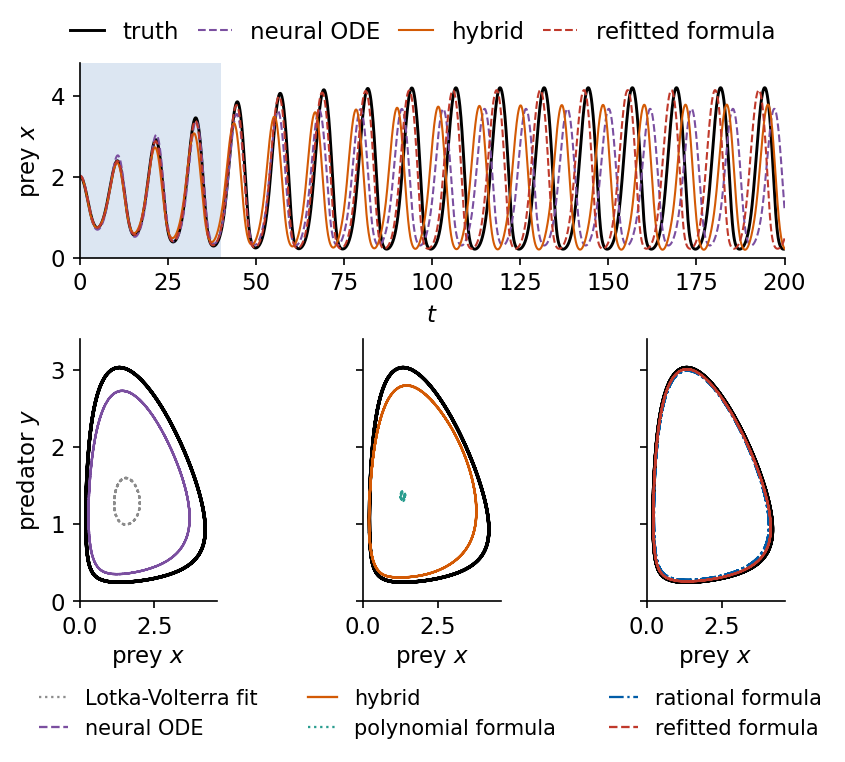

In [18]:
with mpl.rc_context(SLIDE_RC):
    fig = plt.figure(figsize=(5.5, 5.0), layout="constrained")
    gs = fig.add_gridspec(2, 3, height_ratios=[1, 1.35])
    ax = fig.add_subplot(gs[0, :])
    ax.axvspan(0, T_TRAIN, color="#DCE6F2", lw=0, zorder=0)
    ax.plot(t_grid, true[:, 0], **STYLE["truth"], lw=1.4, label="truth")
    for name in ("neural ODE", "hybrid", "refitted formula"):
        ax.plot(t_grid, fc[name][:, 0], **STYLE[name], lw=1.0, label=name)
    ax.set_xlim(0, T_END); ax.set_ylim(0, 4.8); ax.set_xlabel("$t$"); ax.set_ylabel("prey $x$")
    fig.legend(*ax.get_legend_handles_labels(), loc="outside upper center", ncol=4, handlelength=1.5, columnspacing=0.8)
    late = t_grid >= 150
    for i, group in enumerate((("Lotka-Volterra fit", "neural ODE"), ("hybrid", "polynomial formula"), ("rational formula", "refitted formula"))):
        ax = fig.add_subplot(gs[1, i])
        ax.plot(true[late, 0], true[late, 1], color="k", lw=1.6)
        for name in group:
            ax.plot(fc[name][late, 0], fc[name][late, 1], **STYLE[name], lw=1.1, label=name)
        ax.set_xlim(0, 4.6); ax.set_ylim(0, 3.4); ax.set_xlabel("prey $x$")
        if i == 0: ax.set_ylabel("predator $y$")
        else: ax.set_yticklabels([])
        ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.3), handlelength=1.4, fontsize=10, borderaxespad=0.0)
    save(fig, "fig_lab044_forecast"); plt.show()

<hr/>
## 7. Seasonal driving

Prey growth often follows the seasons, for example through rainfall that controls the food of the prey. We model this by a periodic growth rate
$$\alpha(t)=\alpha_0\,\big(1+a\sin\omega t\big),\qquad \alpha_0=1,\quad a=0.2,\quad \omega=\frac{2\pi}{20},$$
with a season of 20 time units, longer than the natural period of the oscillation, while all other terms of the Rosenzweig–MacArthur model stay the same. The driven populations settle into an oscillation whose maxima repeat after three seasons. We record this oscillation after the transient has died out, from $t=300$ to $t=360$, which covers three seasons, with the same sampling and noise as before, and forecast it up to $t=500$. The hybrid model keeps the known terms $\alpha_0x$ and $-\delta y$, so the seasonal part $\alpha_0a\sin(\omega t)\,x$ belongs to the unknown part of the prey equation. We compare two versions. In the first, the network receives the season as two additional inputs, $\mathbf U_\theta(x,y,\sin\omega t,\cos\omega t)$, as an ecologist would do who records the rainfall. In the second, the driver is missing and the network depends on $(x,y)$ only. Both are trained with the same loss and budget.

In [19]:
SEASON, OMEGA = 0.2, 2 * np.pi / 20
T_S0, T_S_TRAIN, T_S_END = 300.0, 60.0, 200.0        # record starts at t = 300, measured for 60, forecast for 200
N_S_TRAIN, N_S_END = int(round(T_S_TRAIN / DT)), int(round(T_S_END / DT))
s_warm = rk4_solve(rosenzweig_macarthur(SEASON, OMEGA), S0_TRUE, 0.0, int(round(T_S0 / DT)), DT, sub=10)[-1]
true_s = np.asarray(rk4_solve(rosenzweig_macarthur(SEASON, OMEGA), s_warm, T_S0, N_S_END, DT, sub=10))
t_s = T_S0 + np.arange(N_S_END + 1) * DT
data_s = measure(true_s[:N_S_TRAIN + 1], np.random.default_rng(5))
t_data_s = t_s[:N_S_TRAIN + 1]
tp_s, xp_s = peaks(t_s, true_s[:, 0])
print("prey maxima of the driven oscillation:", np.round(xp_s[:9], 2))
starts = np.arange(0, N_S_TRAIN - H_SEG + 1)                  # segments of the longer seasonal record
idx = starts[:, None] + np.arange(H_SEG + 1)[None, :]

def f_hybrid_season(params):
    # the network also reads the season through sin(omega t) and cos(omega t)
    def f(s, t):
        z = jnp.concatenate([s / X_SCALE, jnp.array([jnp.sin(OMEGA * t), jnp.cos(OMEGA * t)])])
        return jnp.array([ALPHA * s[0], -DELTA * s[1]]) + mlp(params, z)
    return f

season_fits = {}
for name, f_maker, sizes in (("driver given", f_hybrid_season, [4, 32, 32, 2]), ("driver missing", f_hybrid, SIZES)):
    t0 = time.time()
    p, hist, l_end = train(f_maker, init_mlp(jax.random.PRNGKey(0), sizes, last_scale=0.1), data_s, t_first=T_S0)
    traj = np.asarray(rk4_solve(f_maker(p), jnp.asarray(data_s[0]), T_S0, N_S_END, DT))
    fit_err = float(np.sqrt(np.mean((traj[:N_S_TRAIN + 1, 0] - true_s[:N_S_TRAIN + 1, 0]) ** 2)))
    test_err = float(np.sqrt(np.mean((traj[N_S_TRAIN + 1:, 0] - true_s[N_S_TRAIN + 1:, 0]) ** 2)))
    season_fits[name] = dict(params=p, traj=traj, loss=l_end, fit_err=fit_err, test_err=test_err)
    print(f"{name:15s} prey maxima of the forecast for t > 360:", np.round(peaks(t_s[N_S_TRAIN:], traj[N_S_TRAIN:, 0])[1][:9], 2))
    print(f"{name:15s} loss {l_end:.3e} | rms dx for 300<=t<=360 {fit_err:.3f}, for 360<t<=500 {test_err:.3f}  ({time.time() - t0:.0f} s)")
    nums[f"season_{name}"] = dict(loss=l_end, fit_err=fit_err, test_err=test_err)

prey maxima of the driven oscillation: [5.07 4.05 3.59 5.17 3.99 3.58 5.2  3.93 3.57]


driver given    prey maxima of the forecast for t > 360: [3.66 4.95 4.03 3.66 4.95 4.03 3.66 4.95 4.03]
driver given    loss 9.349e-03 | rms dx for 300<=t<=360 0.096, for 360<t<=500 0.477  (98 s)


driver missing  prey maxima of the forecast for t > 360: [4.15 4.15 4.15 4.15 4.15 4.15 4.15 4.15 4.15]
driver missing  loss 1.831e-02 | rms dx for 300<=t<=360 0.754, for 360<t<=500 0.972  (95 s)


The prey maxima of the driven oscillation follow a pattern of three values, between 5.07 and 5.20, between 3.93 and 4.05 and between 3.57 and 3.59, which repeats every three seasons. The hybrid model that receives the season follows the measured window with a prey error of 0.096 and forecasts the following 140 time units with an error of 0.48. Its forecast repeats the three maxima 4.95, 4.03 and 3.66, as the upper panel shows. Its loss of $9.3\times10^{-3}$ is half that of the model without the driver, $1.8\times10^{-2}$. The model without the driver already fails inside the measured window, with an error of 0.75. Its vector field depends on $(x,y)$ alone, and a trajectory of such an autonomous system in the plane can never cross itself, so every bounded oscillation it produces settles on a closed orbit with a single repeated maximum. The orbit it settles on has all its prey maxima at 4.15, between the true values, and its forecast error is 0.97. More data or a larger network cannot remove this limitation, since it follows from the missing input.

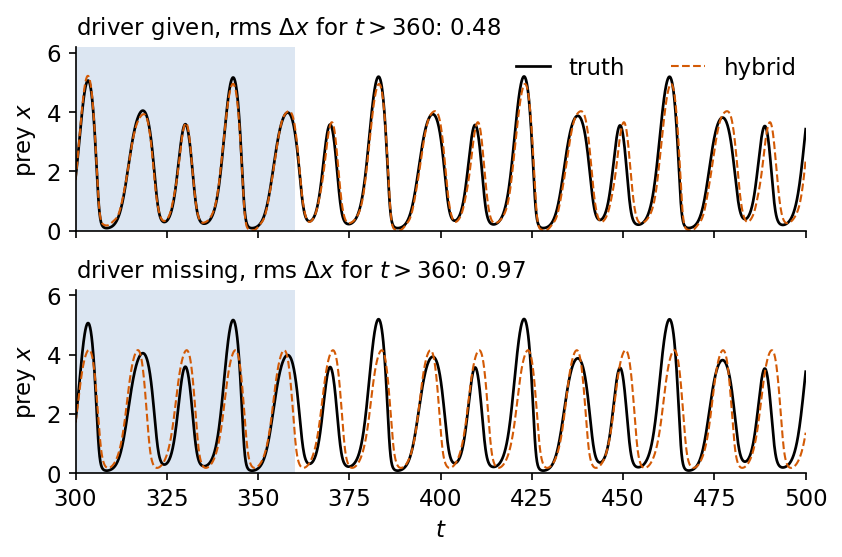

In [20]:
with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(2, 1, figsize=(5.5, 3.6), layout="constrained", sharex=True)
    for ax, name in zip(axs, ("driver given", "driver missing")):
        ax.axvspan(T_S0, T_S0 + T_S_TRAIN, color="#DCE6F2", lw=0, zorder=0)
        ax.plot(t_s, true_s[:, 0], color="k", lw=1.3, label="truth")
        ax.plot(t_s, season_fits[name]["traj"][:, 0], color=DSOrange, lw=1.0, ls="--", label="hybrid")
        ax.set_ylabel("prey $x$"); ax.set_ylim(0, 6.2)
        ax.set_title(name + rf", rms $\Delta x$ for $t>360$: {season_fits[name]['test_err']:.2f}", loc="left")
    axs[0].legend(loc="upper right", ncol=2, handlelength=1.5, borderaxespad=0.0)
    axs[1].set_xlabel("$t$"); axs[1].set_xlim(T_S0, T_S0 + T_S_END)
    save(fig, "fig_lab044_season"); plt.show()

To see whether the network that receives the season has learned the form of the driving term, we regress its prey output $U_1$ on the library $\{x^2,\ R_{h},\ x\sin\omega t,\ x\cos\omega t,\ x,\ y,\ xy\}$ and compare the coefficient of $x\sin\omega t$ with the true $\alpha_0a=0.2$. For the saturation constant we take the refitted value found above, and we print the implicit estimate from the predator output of this network for comparison. STLSQ uses the threshold $\lambda=0.1\,{\rm rms}(U_1)$.

In [21]:
p_s = season_fits["driver given"]["params"]
Z = np.concatenate([data_s / X_SCALE, np.stack([np.sin(OMEGA * t_data_s), np.cos(OMEGA * t_data_s)], 1)], 1)
U_s = np.asarray(mlp(p_s, jnp.asarray(Z)))
xs_, ys_ = data_s[:, 0], data_s[:, 1]
g_s, h_s = np.linalg.lstsq(np.stack([xs_ * ys_, -xs_ * U_s[:, 1]], 1), U_s[:, 1], rcond=None)[0]
print(f"implicit regression of U_2 of this network: gamma = {g_s:.3f}, h = {h_s:.3f}")
SEAS_NAMES = ["x^2", "R_h", "x sin(wt)", "x cos(wt)", "x", "y", "xy"]
Th_s = np.stack([xs_ ** 2, xs_ * ys_ / (1 + h_ref * xs_), xs_ * np.sin(OMEGA * t_data_s), xs_ * np.cos(OMEGA * t_data_s),
                 xs_, ys_, xs_ * ys_], 1)
xi_s_ls = np.linalg.lstsq(Th_s, U_s[:, 0], rcond=None)[0]
xi_s = stlsq(Th_s, U_s[:, 0], 0.1 * np.sqrt(np.mean(U_s[:, 0] ** 2)))
print(f"with h = {h_ref:.3f}, least squares: U_1 = {formula(xi_s_ls, SEAS_NAMES)}")
print(f"with h = {h_ref:.3f}, STLSQ:         U_1 = {formula(xi_s, SEAS_NAMES)}")
print(f"true: U_1 = {-ALPHA / K_CAP:+.3f} x^2 {-BETA:+.3f} R_h {ALPHA * SEASON:+.3f} x sin(wt)  with h = {H_SAT}")
nums["season_h_implicit"] = float(h_s); nums["season_xi"] = dict(zip(SEAS_NAMES, xi_s.tolist()))

implicit regression of U_2 of this network: gamma = 0.894, h = 0.415
with h = 0.492, least squares: U_1 = -0.163 x^2 -0.992 R_h +0.188 x sin(wt) -0.001 x cos(wt) -0.016 x +0.002 y +0.007 xy
with h = 0.492, STLSQ:         U_1 = -0.166 x^2 -0.981 R_h +0.193 x sin(wt)
true: U_1 = -0.167 x^2 -1.000 R_h +0.200 x sin(wt)  with h = 0.5


Least squares on all seven columns gives the coefficient 0.188 of $x\sin\omega t$, and STLSQ keeps three terms, $U_1=-0.166\,x^2-0.981\,R_h+0.193\,x\sin\omega t$, against the true $-0.167\,x^2-R_h+0.2\,x\sin\omega t$. The network has thus learned the seasonal modulation of the prey growth rate with its amplitude and phase, $\alpha_0a=0.193$ for the true 0.2, together with the interaction. The implicit estimate of $h$ from this network, 0.415, is less accurate than the one from the undriven record, which is why we used the refitted value.
<hr/>
## Summary

We fitted three models to noisy predator–prey counts generated by the Rosenzweig–MacArthur model, a Holling type II predator and a prey with finite carrying capacity. The textbook Lotka–Volterra equations fit the measured window only by distorting all four rates and forecast a small closed orbit in place of the limit cycle. The neural ODE and the hybrid model fit the data about as well as the noise permits, and both produce a limit cycle whose prey maximum is 10 to 12 per cent too small and whose period is 6 to 7 per cent too short, because the cycle extends beyond the region covered by the measured spiral. The hybrid model, which keeps the known terms $\alpha x$ and $-\delta y$, learns the unknown part of the vector field with an error of about 2 per cent on the data.

Sparse regression on this learned function separates what the data can and cannot fix. A polynomial library reproduces the network on the data, but the result is a truncated Taylor series of the saturating interaction that fails outside the data. A library linear in its coefficients cannot contain the saturation constant $h$, and a grid of rational columns produces large cancelling coefficients. Multiplying the predator equation by the denominator makes the problem linear in $\gamma$ and $h$, and the implicit regression finds $\hat h=0.474$ for the true 0.5. With this column STLSQ selects the two terms of the true prey equation and the single term of the predator equation, and a refit of the four remaining numbers through the solver brings them within 2 per cent of the truth. The refitted equation reproduces the period of the true limit cycle to 1 per cent and its prey maximum to 1.4 per cent.

A seasonal driver of the prey growth must be given to the network as an input. With $\sin\omega t$ and $\cos\omega t$ among its inputs the hybrid model reproduces a driven oscillation whose maxima repeat after three seasons. Without them, the model is an autonomous system in the plane and can produce only an oscillation with equal maxima, so it fails already in the measured window.

These results refer to one noisy record of each kind, a noise level of 5 per cent and the known rates $\alpha$ and $\delta$. The implicit regression needs a guess of the form of the denominator, and with a different hidden interaction the library would have to be extended accordingly.

## References

- A. J. Lotka, *Analytical note on certain rhythmic relations in organic systems*, PNAS **6**, 410 (1920), [doi:10.1073/pnas.6.7.410](https://doi.org/10.1073/pnas.6.7.410)
- V. Volterra, *Fluctuations in the abundance of a species considered mathematically*, Nature **118**, 558 (1926), [doi:10.1038/118558a0](https://doi.org/10.1038/118558a0)
- C. S. Holling, *Some characteristics of simple types of predation and parasitism*, Can. Entomol. **91**, 385 (1959), [doi:10.4039/Ent91385-7](https://doi.org/10.4039/Ent91385-7)
- M. L. Rosenzweig, R. H. MacArthur, *Graphical representation and stability conditions of predator-prey interactions*, Am. Nat. **97**, 209 (1963), [doi:10.1086/282272](https://doi.org/10.1086/282272)
- C. Rackauckas, Y. Ma, J. Martensen, C. Warner, K. Zubov, R. Supekar, D. Skinner, A. Ramadhan, A. Edelman, *Universal Differential Equations for Scientific Machine Learning*, [arXiv:2001.04385](https://arxiv.org/abs/2001.04385)
- S. L. Brunton, J. L. Proctor, J. N. Kutz, *Discovering governing equations from data by sparse identification of nonlinear dynamical systems*, PNAS **113**, 3932 (2016), [doi:10.1073/pnas.1517384113](https://doi.org/10.1073/pnas.1517384113)
- N. M. Mangan, S. L. Brunton, J. L. Proctor, J. N. Kutz, *Inferring biological networks by sparse identification of nonlinear dynamics*, IEEE Trans. Mol. Biol. Multi-Scale Commun. **2**, 52 (2016), [doi:10.1109/TMBMC.2016.2633265](https://doi.org/10.1109/TMBMC.2016.2633265)
- R. T. Q. Chen, Y. Rubanova, J. Bettencourt, D. Duvenaud, *Neural Ordinary Differential Equations*, [arXiv:1806.07366](https://arxiv.org/abs/1806.07366)
- P. Kidger, *On Neural Differential Equations*, PhD thesis, University of Oxford (2021), [arXiv:2202.02435](https://arxiv.org/abs/2202.02435)
- Ch. Tsitouras, *Runge–Kutta pairs of order 5(4) satisfying only the first column simplifying assumption*, Comput. Math. Appl. **62**, 770 (2011), [doi:10.1016/j.camwa.2011.06.002](https://doi.org/10.1016/j.camwa.2011.06.002)
- D. P. Kingma, J. Ba, *Adam: a method for stochastic optimization*, [arXiv:1412.6980](https://arxiv.org/abs/1412.6980)

The last cell collects the numbers of this notebook in a JSON file and as LaTeX macros.

In [22]:
nums["runtime_s"] = round(time.time() - t_start, 1)
def to_py(o):
    if isinstance(o, dict): return {str(k): to_py(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [to_py(v) for v in o]
    if isinstance(o, (np.floating, np.integer)): return o.item()
    return o
with open(f"{OUT}/numbers_lab044.json", "w") as fh:
    json.dump(to_py(nums), fh, indent=1)

# LaTeX macros \labfortyfour... (letters only) for the numbers the slides use
MODTAG = {"Lotka-Volterra fit": "LVFit", "neural ODE": "NeuralODE", "hybrid": "Hybrid",
          "polynomial formula": "PolyFormula", "rational formula": "RatFormula", "refitted formula": "RefitFormula"}
macros = {}
for m in MODEL_NAMES:
    s_ = scores[m]
    macros[f"RmsFirst{MODTAG[m]}"] = f"{s_['rms_first']:.3f}"
    macros[f"Period{MODTAG[m]}"] = f"{s_['period']:.2f}"
    macros[f"Xmax{MODTAG[m]}"] = f"{s_['x_max']:.2f}"
    macros[f"Xmin{MODTAG[m]}"] = f"{s_['x_min']:.3f}"
macros["PeriodTruth"] = f"{cyc_true['period']:.2f}"; macros["XmaxTruth"] = f"{cyc_true['x_max']:.2f}"
macros["XminTruth"] = f"{cyc_true['x_min']:.3f}"
macros["XmaxTrain"] = f"{nums['x_max_train']:.2f}"
macros["LVAlpha"], macros["LVBeta"], macros["LVGamma"], macros["LVDelta"] = [f"{r:.3f}" for r in rates]
macros["UErrOne"], macros["UErrTwo"] = [f"{r:.3f}" for r in nums["U_rel_err"]]
macros["UTwoErrCycle"] = f"{nums['U2_err_on_cycle']:.2f}"
macros["GammaHat"], macros["HHat"] = f"{gamma_hat:.3f}", f"{h_hat:.3f}"
macros["HRefit"] = f"{h_ref:.3f}"
macros["RefitXsq"] = f"{xi_ref[0][2]:.3f}"; macros["RefitROne"] = f"{xi_ref[0][5]:.3f}"; macros["RefitRTwo"] = f"{xi_ref[1][5]:.3f}"
macros["HScanLo"], macros["HScanHi"] = f"{nums['h_scan_lo']:.2f}", f"{nums['h_scan_hi']:.2f}"
macros["RatXsq"] = f"{xi_rat[0][2]:.3f}"; macros["RatROne"] = f"{xi_rat[0][5]:.3f}"; macros["RatRTwo"] = f"{xi_rat[1][5]:.3f}"
macros["PolyResOne"], macros["PolyResTwo"] = [f"{r:.3f}" for r in nums["poly_res_0.2"]]
macros["Params"] = str(nums["n_params"]); macros["Sigma"] = f"{SIGMA:g}"; macros["NData"] = str(nums["n_data"])
macros["EigReal"] = f"{nums['eig_rm_real']:.4f}"
macros["SeasonGivenTest"] = f"{nums['season_driver given']['test_err']:.3f}"
macros["SeasonMissingTest"] = f"{nums['season_driver missing']['test_err']:.3f}"
macros["SeasonGivenFit"] = f"{nums['season_driver given']['fit_err']:.3f}"
macros["SeasonMissingFit"] = f"{nums['season_driver missing']['fit_err']:.3f}"
macros["SeasonSinCoef"] = f"{nums['season_xi']['x sin(wt)']:.3f}"
macros["SeasonHImplicit"] = f"{nums['season_h_implicit']:.3f}"
macros["GradDiff"] = f"{nums['grad_rel_diff']:.1e}".split("e")[0] + "\\times10^{" + str(int(f"{nums['grad_rel_diff']:.1e}".split("e")[1])) + "}"
macros["Runtime"] = f"{nums['runtime_s'] / 60:.1f}"
bad = [k for k in macros if not k.isalpha()]
assert not bad, bad
with open(f"{OUT}/nb_numbers_lab044.tex", "w") as fh:
    for k, val in macros.items():
        fh.write(f"\\newcommand{{\\labfortyfour{k}}}{{{val}}}\n")
print(f"{len(macros)} macros written; total runtime {nums['runtime_s'] / 60:.1f} min")

60 macros written; total runtime 5.5 min
